In [1]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

print("Built with CUDA:", tf.test.is_built_with_cuda())

TensorFlow: 2.10.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Built with CUDA: True


In [3]:
import sys
import numpy as np
import pip

print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("NumPy version:", np.__version__)
print("Python path:", sys.prefix)

Python version: 3.10.0 (tags/v3.10.0:b494f59, Oct  4 2021, 19:00:18) [MSC v.1929 64 bit (AMD64)]
Python executable: c:\Users\lenovo\OneDrive\Desktop\deep learning\.venv\Scripts\python.exe
NumPy version: 1.23.5
Python path: c:\Users\lenovo\OneDrive\Desktop\deep learning\.venv


In [11]:
from tensorflow import  keras
from keras.layers import Dense , Conv2D, MaxPool2D, Flatten
from keras import models

In [5]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [ ]:
X_train = X_train / 255.0

X_test = X_test / 255.0

In [24]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [25]:
model = models.Sequential([
    Conv2D(64, (3,3), activation="relu", input_shape=(28, 28, 1)),
    MaxPool2D((2,2)),

    Conv2D(32, (3,3), activation="relu"),
    MaxPool2D((2,2)),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [26]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [27]:
model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
)

Epoch 1/10
1875/1875 [==============================] - 17s 8ms/step - loss: 0.1509 - accuracy: 0.9543
Epoch 2/10
1875/1875 [==============================] - 12s 6ms/step - loss: 0.0483 - accuracy: 0.9849
Epoch 3/10
1875/1875 [==============================] - 12s 7ms/step - loss: 0.0332 - accuracy: 0.9897
Epoch 4/10
1875/1875 [==============================] - 12s 7ms/step - loss: 0.0245 - accuracy: 0.9922
Epoch 5/10
1875/1875 [==============================] - 16s 9ms/step - loss: 0.0195 - accuracy: 0.9938
Epoch 6/10
1875/1875 [==============================] - 14s 7ms/step - loss: 0.0154 - accuracy: 0.9953
Epoch 7/10
1875/1875 [==============================] - 14s 7ms/step - loss: 0.0122 - accuracy: 0.9962
Epoch 8/10
1875/1875 [==============================] - 14s 8ms/step - loss: 0.0110 - accuracy: 0.9965
Epoch 9/10
1875/1875 [==============================] - 14s 8ms/step - loss: 0.0093 - accuracy: 0.9969
Epoch 10/10
1875/1875 [==============================] - 14s 8ms/step - l

In [28]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1 (Conv2D)           (None, 26, 26, 64)        640       
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 13, 13, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 11, 11, 32)        18464     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten_1 (Flatten)         (None, 800)               0         
                                                                 
 dense_2 (Dense)             (None, 64)               

In [29]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Accuracy:", accuracy)

313/313 [==============================] - 4s 11ms/step - loss: 0.0340 - accuracy: 0.9912
Accuracy: 0.9911999702453613


In [30]:
predictions = model.predict(X_test[:5])

for i in range(5):
    print("Predicted:", predictions[i].argmax())
    print("Actual:", y_test[i])

1/1 [==============================] - 0s 240ms/step
Predicted: 7
Actual: 7
Predicted: 2
Actual: 2
Predicted: 1
Actual: 1
Predicted: 0
Actual: 0
Predicted: 4
Actual: 4


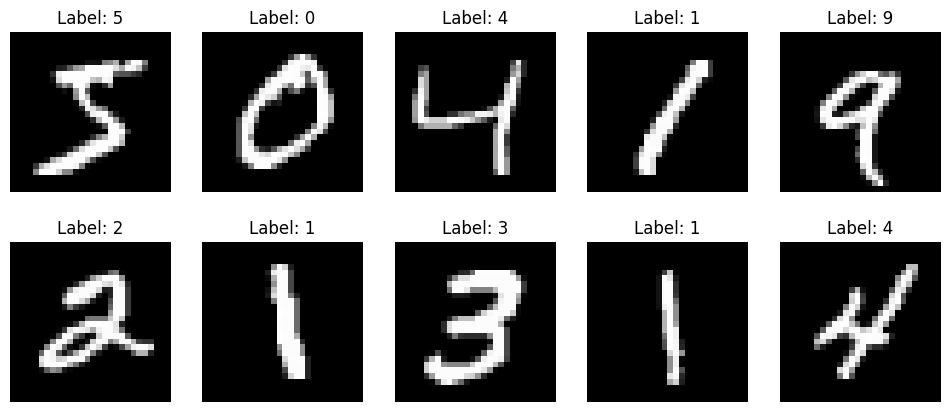

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[i], cmap='gray')

    plt.title(f"Label: {y_train[i]}")

    plt.axis('off')

plt.show()